In [1]:
import numpy as np
import torch
import torch.nn as nn
import os
from tqdm import tqdm
from torch.utils.data import TensorDataset, DataLoader

In [2]:
batch_size = 32
x_dim = 1
input_len = 10000

In [3]:
# output_dir = "dataset_splits"
# data = np.load("dataset_splits/dataset_train.npz")
# valorPsi = data["psi"]
# valorM = data["M"]
# print("valorPsi:", valorPsi)
# print("valorM:", valorM)

In [4]:
open_dir = "dataset_splits"

def carregar_dados(nome):
    data = np.load(os.path.join(open_dir, nome))
    psi = data["psi"]
    M = data["M"]
    return psi, M

psi_train, M_train = carregar_dados("dataset_train.npz")
psi_val, M_val = carregar_dados("dataset_val.npz")
psi_test, M_test = carregar_dados("dataset_test.npz")

In [5]:
psi_mean, psi_std = np.mean(psi_train), np.std(psi_train)
M_mean, M_std = np.mean(M_train), np.std(M_train)

def normalization(psi, M):
    return (psi - psi_mean) / psi_std, (M - M_mean) / M_std

psi_train, M_train = normalization(psi_train, M_train)
psi_val, M_val = normalization(psi_val, M_val)
psi_test, M_test = normalization(psi_test, M_test)

def toTensor(psi, M):
    y = torch.tensor(psi, dtype=torch.float64).unsqueeze(1)
    x = torch.tensor(M, dtype=torch.float64).unsqueeze(1)

    # print("----- DEBUG: para_tensor -----")
    # print(f"y.shape: {y.shape}  | y.dtype: {y.dtype}")
    # print(f"x.shape: {x.shape}  | x.dtype: {x.dtype}")
    # print(f"y[0] (primeiro exemplo, canal 0, 10 primeiros pontos): {y[0, 0, :10]}")
    # print(f"x[0] (valor de M do primeiro exemplo): {x[0]}")
    # print(f"y[-1] (último exemplo, 10 primeiros pontos): {y[-1, 0, :10]}")
    # print(f"x[-1] (valor de M do último exemplo): {x[-1]}")
    # print("-------------------------------")
    return y, x

y_train, x_train = toTensor(psi_train, M_train)
y_val, x_val = toTensor(psi_val, M_val)
y_test, x_test = toTensor(psi_test, M_test)


In [6]:
train_loader = DataLoader(TensorDataset(x_train, y_train), batch_size=batch_size, shuffle=True)
val_loader = DataLoader(TensorDataset(x_val, y_val), batch_size=batch_size, shuffle=False)
test_loader = DataLoader(TensorDataset(x_test, y_test), batch_size=batch_size, shuffle=False)

In [ ]:
class ExtratoFeature(nn.Module):
    # bloco conv compartilhado
    def __init__(self, input_len = 10000):
        super().__init__()
        self.conv = nn.Sequential(
            # L_out = (L_in + 2 * padding - kernel_size)/stride + 1
            nn.Conv1d(1, 16, kernel_size = 5, stride = 4, padding = 2), # (10000 + 2*2 - 5)/4 + 1 = 2500
            nn.LeakyReLU(0.2),
            nn.Conv1d(16, 32, kernel_size = 5, stride = 4, padding = 2), # (2500 + 2*2 - 5)/4 + 1 = 625
            nn.LeakyReLU(0.2),
            nn.Conv1d(32, 64, kernel_size = 5, stride = 4, padding = 2), # (625 + 2*2 - 5)/4 + 1 = 156
            nn.LeakyReLU(0.2),
        )
        with torch.no_grad():
            dummy = torch.zeros(1, 1, input_len)
            out = self.conv(dummy)
            self.flat_dim = out.view(1, -1).shape[1]

    def forward(self, y):
        # y = [batch, 1, input_len]
        h = self.conv(y)
        return h.view(h.size(0), -1)

In [8]:
class PriorNet(nn.Module):
    def __init__(self, flat_dim, n_z):
        super().__init__()
        self.fc = nn.Sequential(
            nn.Linear(flat_dim, 256),
            nn.LeakyReLU(0.2),
            nn.Linear(256, 128),
            nn.LeakyReLU(0.2),
        )
        self.fc_mean = nn.Linear(128, n_z)
        self.fc_logvar = nn.Linear(128, n_z)

    def forward(self, y_features):
        # espera-se saida achatada do extratorFeature
        h = self.fc(y_features)
        mean_p = self.fc_mean(h)
        logvar_p = self.fc_logvar(h)
        return mean_p, logvar_p

In [9]:
class Encoder(nn.Module):
    def __init__(self, flat_dim, x_dim, n_z):
        super().__init__()
        self.fc = nn.Sequential(
            nn.Linear(flat_dim + x_dim, 256),
            nn.LeakyReLU(0.2),
            nn.Linear(256, 128),
            nn.LeakyReLU(0.2),
        )
        self.fc_mean = nn.Linear(128, n_z)
        self.fc_logvar = nn.Linear(128, n_z)

    def forward(self, y_features, x):
        h_in = torch.cat([y_features, x], dim=1)
        h = self.fc(h_in)
        mean_q = self.fc_mean(h)
        logvar_q = self.fc_logvar(h)
        return mean_q, logvar_q

In [10]:
class Decoder(nn.Module):
    def __init__(self, flat_dim, x_dim, n_z):
        super().__init__()
        self.fc = nn.Sequential(
            nn.Linear(flat_dim + n_z, 256),
            nn.LeakyReLU(0.2),
            nn.Linear(256, 128),
            nn.LeakyReLU(0.2),
        )
        self.fc_mean = nn.Linear(128, x_dim)
        self.fc_logvar = nn.Linear(128, x_dim)

    def forward(self, y_features, x):
        h_in = torch.cat([y_features, x], dim=1)
        h = self.fc(h_in)
        mean_x = self.fc_mean(h)
        logvar_x = self.fc_logvar(h)
        return mean_x, logvar_x

In [11]:
class CVAE(nn.Module):
    def __init__(self, input_len, x_dim, n_z = 4):
        super().__init__()
        self.feature_extractor = ExtratoFeature(input_len)
        flat_dim = self.feature_extractor.flat_dim

        self.prior_net = PriorNet(flat_dim, n_z)
        self.encoder = Encoder(flat_dim, x_dim, n_z)
        self.decoder = Decoder(flat_dim, x_dim, n_z)

    def reparameterize(self, mean, logvar):
        std = torch.exp(0.5 * logvar)
        eps = torch.randn_like(std)
        return mean + eps * std

    def forward(self, x, y):
        # y = [batch, 1, input_len], x = [batch, x_dim]
        y_features = self.feature_extractor(y)
        mean_p, logvar_p = self.prior_net(y_features)
        mean_q, logvar_q = self.encoder(y_features, x)
        z = self.reparameterize(mean_q, logvar_q)
        mean_x, logvar_x = self.decoder(y_features, z)
        return mean_x, logvar_x, mean_q, logvar_q, mean_p, logvar_p

    def sample(self, y, num_samples = 1000):
        #inferência realiza amostragem do prior p(z|y) e gera amostras de x
        self.eval()
        with torch.no_grad():
            y_features = self.feature_extractor(y)
            mean_p, logvar_p = self.prior_net(y_features)
            # aqui fala para gerar varias amostras do mesmo y, qual o sentido?
            mean_p = mean_p.repeat(num_samples, 1)
            logvar_p = logvar_p.repeat(num_samples, 1)
            y_features_rep = y_features.repeat(num_samples, 1)
            z = self.reparameterize(mean_p, logvar_p)
            mean_x, logvar_x = self.decoder(y_features_rep, z)
            x_samples = self.reparameterize(mean_x, logvar_x)
        return x_samples

In [12]:
def loss_cvae_gw(x, mean_x, logvar_x, mean_q, logvar_q, mean_p, logvar_p):
    # Reconstrução: -log N(x; mean_x, exp(logvar_x)), variância APRENDIDA, não fixa
    var_x = logvar_x.exp()
    recon_loss = torch.sum(
        (x - mean_x).pow(2) / (2 * var_x) + 0.5 * logvar_x,
        dim=1  # soma sobre as dimensões de x (o "i" da reconstrução, se x_dim > 1)
    )

    # KL entre q_phi(z|x,y) e r_theta1(z|y)
    var_q = logvar_q.exp()
    var_p = logvar_p.exp()
    kl = torch.sum(
        0.5 * (logvar_p - logvar_q) + (var_q + (mean_q - mean_p).pow(2)) / (2 * var_p) - 0.5,
        dim=1  # soma sobre as dimensões de z (o "i" do KL)
    )

    H = torch.mean(recon_loss + kl)  # média sobre o batch (o "1/N * sum_n")
    return H

In [13]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = CVAE(input_len, x_dim, n_z=4).double().to(device)
optimizer = torch.optim.Adam(model.parameters(), lr=1e-4)
from torchinfo import summary

input_shapes = [(batch_size, x_dim), (batch_size, 1, input_len)]

summary(model, input_size=input_shapes, dtypes=[torch.float64, torch.float64])

Layer (type:depth-idx)                   Output Shape              Param #
CVAE                                     [32, 1]                   --
├─ExtratoFeature: 1-1                    [32, 10048]               --
│    └─Sequential: 2-1                   [32, 64, 157]             --
│    │    └─Conv1d: 3-1                  [32, 16, 2500]            96
│    │    └─LeakyReLU: 3-2               [32, 16, 2500]            --
│    │    └─Conv1d: 3-3                  [32, 32, 625]             2,592
│    │    └─LeakyReLU: 3-4               [32, 32, 625]             --
│    │    └─Conv1d: 3-5                  [32, 64, 157]             10,304
│    │    └─LeakyReLU: 3-6               [32, 64, 157]             --
├─PriorNet: 1-2                          [32, 4]                   --
│    └─Sequential: 2-2                   [32, 128]                 --
│    │    └─Linear: 3-7                  [32, 256]                 2,572,544
│    │    └─LeakyReLU: 3-8               [32, 256]                 --
│

In [14]:
def mae_metric(x, mean_x):
    return torch.mean(torch.abs(x - mean_x)).item()

In [15]:
history = {"train_loss": [], "val_loss": [], "train_mae": [], "val_mae": []}

n_epoch = 50
for epoch in tqdm(range(n_epoch), desc="Épocas"):
    # --- treino ---
    model.train()
    train_loss, train_mae = 0.0, 0.0
    for x_batch, y_batch in train_loader:
        x_batch = x_batch.double().to(device)
        y_batch = y_batch.double().to(device)

        optimizer.zero_grad()
        mean_x, logvar_x, mean_q, logvar_q, mean_p, logvar_p = model(x_batch, y_batch)
        loss = loss_cvae_gw(x_batch, mean_x, logvar_x, mean_q, logvar_q, mean_p, logvar_p)
        loss.backward()
        optimizer.step()

        train_loss += loss.item()
        train_mae += mae_metric(x_batch, mean_x)

    # --- validação ---
    model.eval()
    val_loss, val_mae = 0.0, 0.0
    with torch.no_grad():
        for x_batch, y_batch in val_loader:
            x_batch = x_batch.double().to(device)
            y_batch = y_batch.double().to(device)
            mean_x, logvar_x, mean_q, logvar_q, mean_p, logvar_p = model(x_batch, y_batch)
            loss = loss_cvae_gw(x_batch, mean_x, logvar_x, mean_q, logvar_q, mean_p, logvar_p)

            val_loss += loss.item()
            val_mae += mae_metric(x_batch, mean_x)

    # médias por época
    history["train_loss"].append(train_loss / len(train_loader))
    history["val_loss"].append(val_loss / len(val_loader))
    history["train_mae"].append(train_mae / len(train_loader))
    history["val_mae"].append(val_mae / len(val_loader))

    print(f"Epoch {epoch+1}/{n_epoch} | Train Loss: {history['train_loss'][-1]:.4f} | "
          f"Val Loss: {history['val_loss'][-1]:.4f} | Train MAE: {history['train_mae'][-1]:.4f} | "
          f"Val MAE: {history['val_mae'][-1]:.4f}")

Épocas:   2%|▏         | 1/50 [01:05<53:50, 65.93s/it]

Epoch 1/50 | Train Loss: -1.7789 | Val Loss: -2.5426 | Train MAE: 0.1245 | Val MAE: 0.0106


Épocas:   4%|▍         | 2/50 [02:05<49:49, 62.28s/it]

Epoch 2/50 | Train Loss: -1.9675 | Val Loss: -2.7938 | Train MAE: 0.0292 | Val MAE: 0.0087


Épocas:   6%|▌         | 3/50 [03:08<49:04, 62.65s/it]

...

Epoch 48/50 | Train Loss: -3.9485 | Val Loss: -4.2292 | Train MAE: 0.0049 | Val MAE: 0.0018


Épocas:  98%|█████████▊| 49/50 [42:15<00:48, 48.34s/it]

Epoch 49/50 | Train Loss: -3.4458 | Val Loss: -3.7138 | Train MAE: 0.0070 | Val MAE: 0.0030


Épocas: 100%|██████████| 50/50 [43:04<00:00, 51.68s/it]

Epoch 50/50 | Train Loss: -3.9629 | Val Loss: -3.7197 | Train MAE: 0.0039 | Val MAE: 0.0130


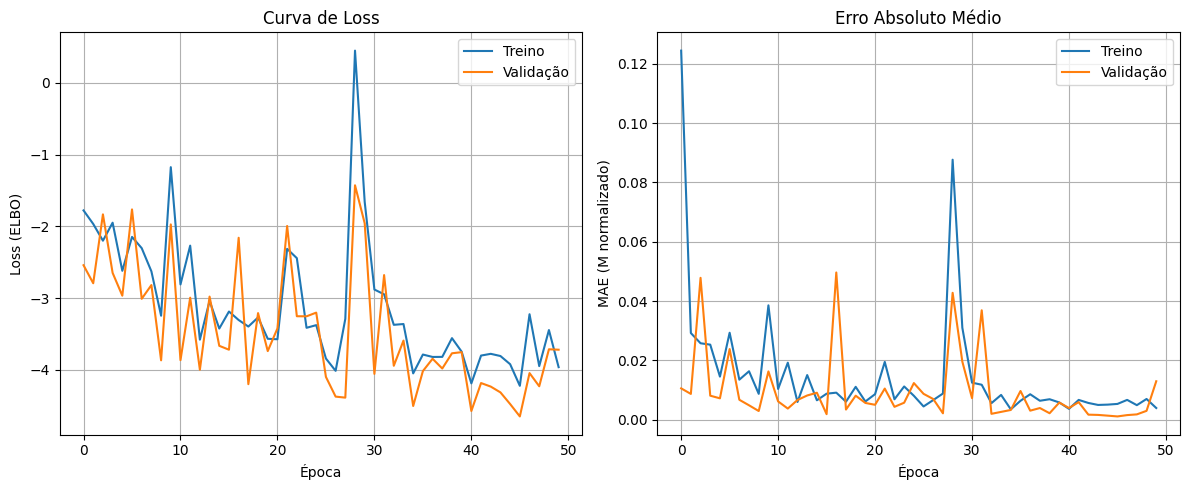

In [16]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].plot(history["train_loss"], label="Treino")
axes[0].plot(history["val_loss"], label="Validação")
axes[0].set_xlabel("Época")
axes[0].set_ylabel("Loss (ELBO)")
axes[0].set_title("Curva de Loss")
axes[0].legend()
axes[0].grid(True)

axes[1].plot(history["train_mae"], label="Treino")
axes[1].plot(history["val_mae"], label="Validação")
axes[1].set_xlabel("Época")
axes[1].set_ylabel("MAE (M normalizado)")
axes[1].set_title("Erro Absoluto Médio")
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.show()